### Objesctive 
#### To identify different segments in the existing customers based on their spending patterns, and past interaction with the bank.

In [334]:
### Import all necessary libraries and functions

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns 
sns.set_theme()
### import zscore so that we can scale the columns
from scipy.stats import zscore

from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage,cophenet
from sklearn.metrics import silhouette_score
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer



In [335]:
# Reading the dataset 
custdata=pd.read_csv('Credit Card Customer Data.csv')

In [336]:
custdata.head(10)

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3
5,6,58634,20000,3,0,1,8
6,7,48370,100000,5,0,11,2
7,8,37376,15000,3,0,1,1
8,9,82490,5000,2,0,2,2
9,10,44770,3000,4,0,1,7


In [337]:
# lets us look at the structure of the data
custdata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


###### There are no null values in the data. 7 columns are of thr object type and the rest are numerical. 

### Missing value Treatment - Duplicate observations check and removal 

In [338]:
# lets check duplicate observations
df.duplicated().sum()

0

In [339]:
df = df[(~df.duplicated())].copy()

In [340]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Avg_Credit_Limit,649.000,34878.274,37813.737,3000.000,11000.000,18000.000,49000.000,200000.000
Total_Credit_Cards,649.000,4.709,2.174,1.000,3.000,5.000,6.000,10.000
Total_visits_bank,649.000,2.398,1.625,0.000,1.000,2.000,4.000,5.000
Total_visits_online,649.000,2.624,2.953,0.000,1.000,2.000,4.000,15.000
Total_calls_made,649.000,3.590,2.878,0.000,1.000,3.000,5.000,10.000
K_means_segments,649.000,0.737,0.590,0.000,0.000,1.000,1.000,2.000


In [341]:
custdata = data.copy()
## we won't need customer key or SI No so let's drop them
custdata.drop('Customer_Key',axis=1,inplace=True)

In [342]:
custdata.drop('Sl_No', axis=1,inplace=True)

In [343]:
custdata.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


In [344]:
# checking missing values
df.isna().sum()

Avg_Credit_Limit       0
Total_Credit_Cards     0
Total_visits_bank      0
Total_visits_online    0
Total_calls_made       0
K_means_segments       0
dtype: int64

### EDA

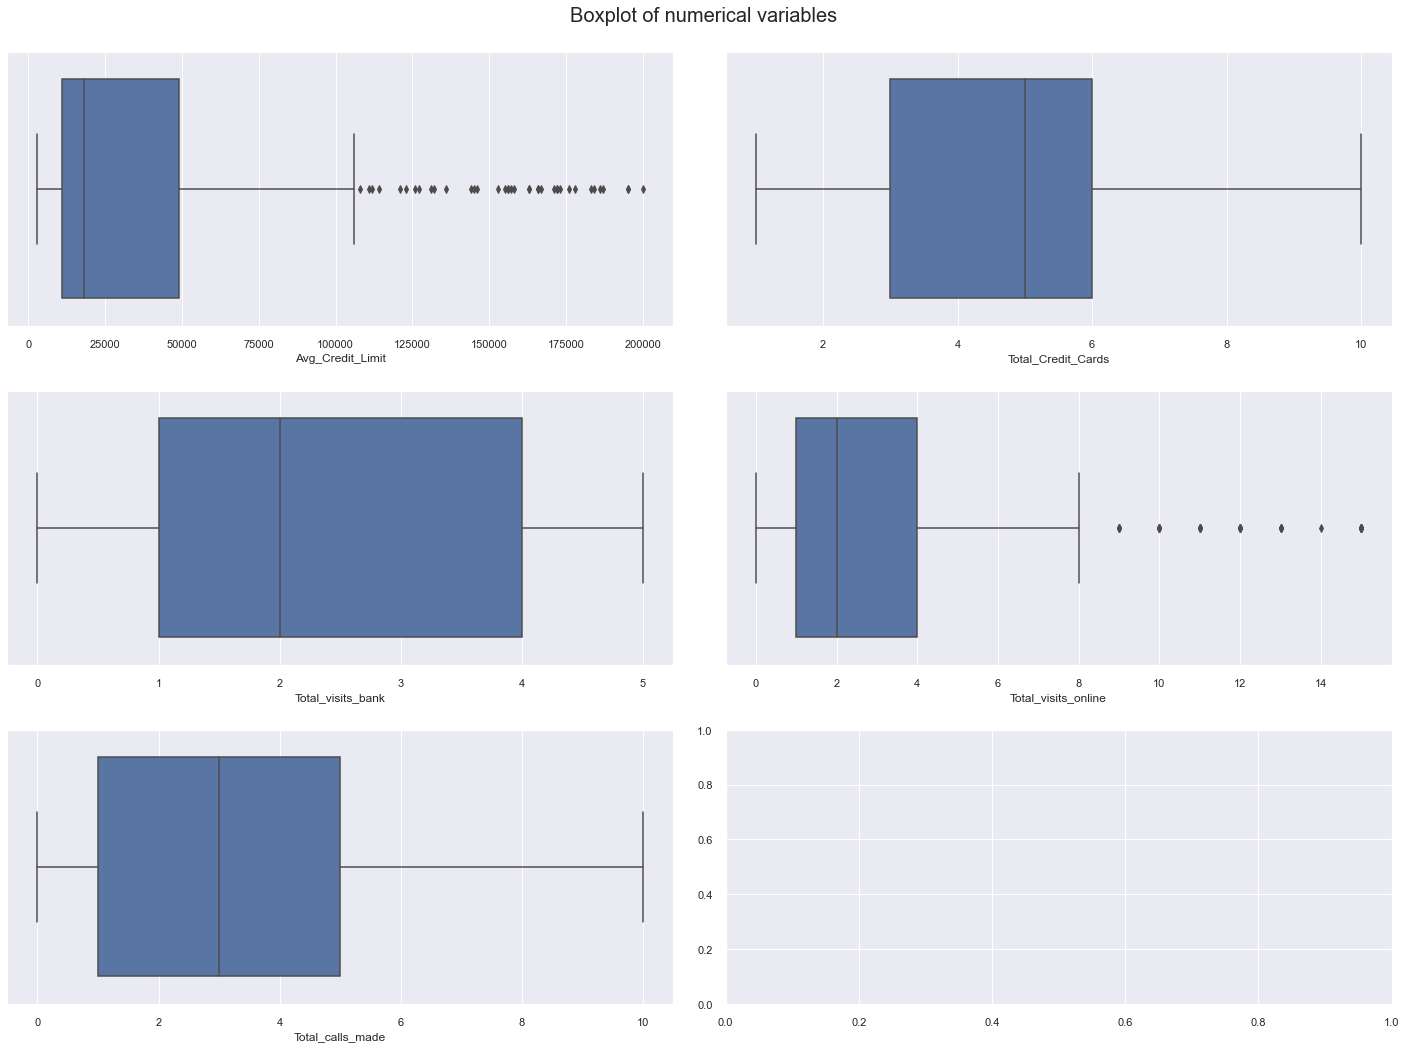

In [256]:
# selecting numerical columns
all_col = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(3, 2,  figsize=(20, 15))
fig.suptitle('Boxplot of numerical variables', fontsize=20)
counter = 0
for ii in range(3):
    sns.boxplot(ax=axes[ii][0],x=df[all_col[counter]])
    counter = counter+1
    if counter != 5:
        sns.boxplot(ax=axes[ii][1],x=df[all_col[counter]])
        counter = counter+1
    else:
        pass

fig.tight_layout(pad=2.0)

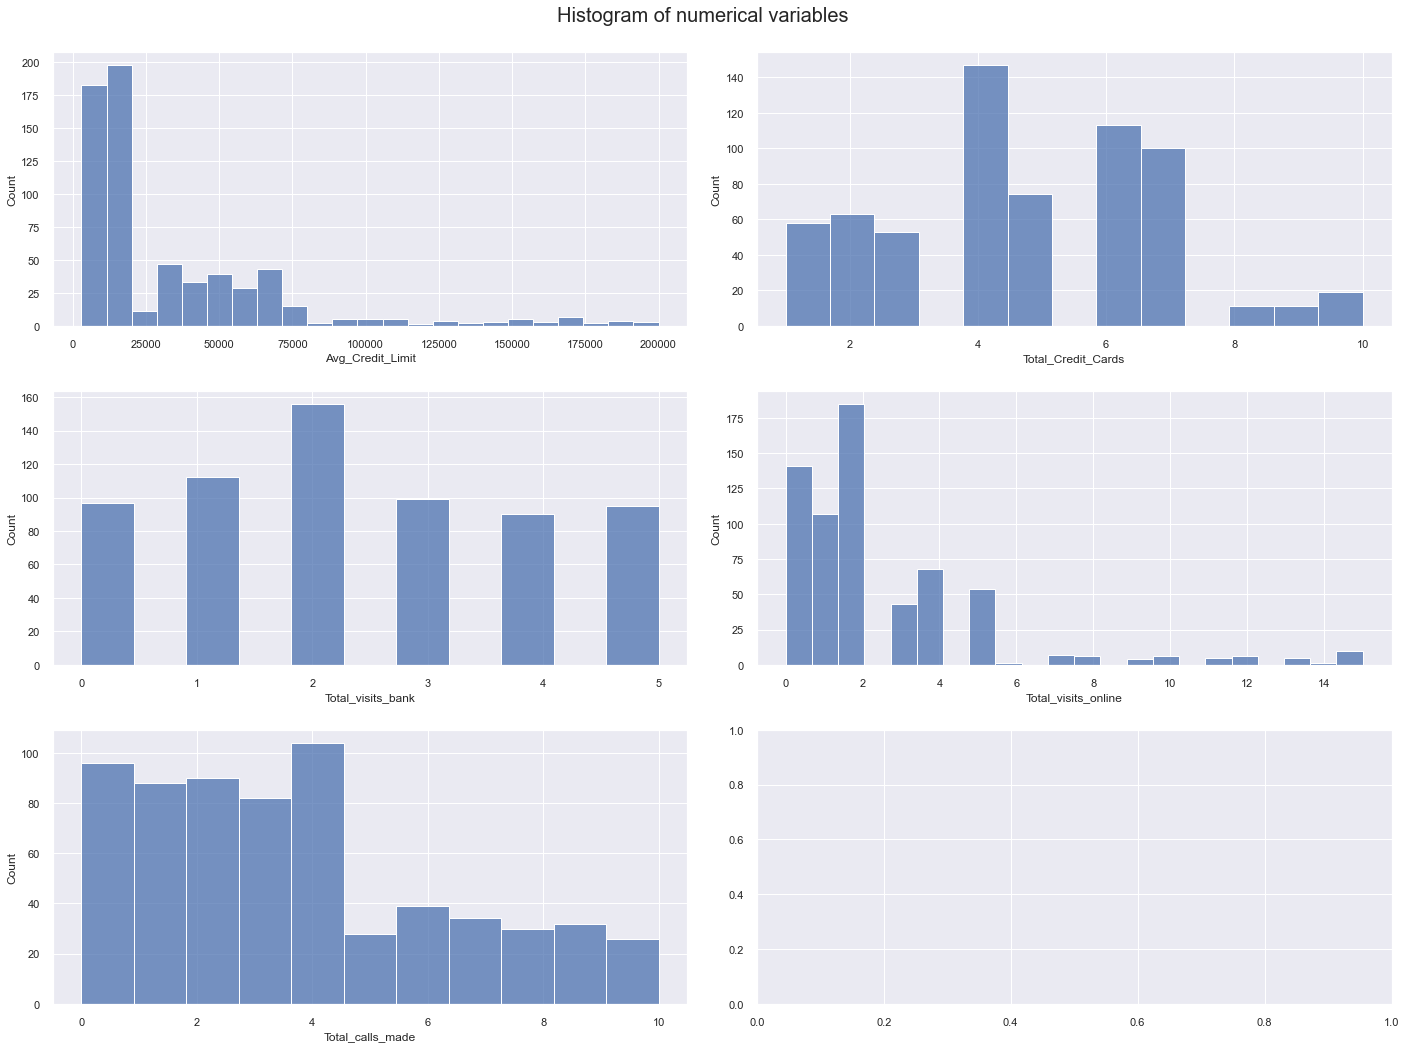

In [257]:
# select numerical columns
all_col = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(3, 2,  figsize=(20, 15))
fig.suptitle('Histogram of numerical variables', fontsize=20)
counter = 0
for ii in range(3):
    sns.histplot(ax=axes[ii][0],x=df[all_col[counter]])
    counter = counter+1
    if counter != 5:
        sns.histplot(ax=axes[ii][1],x=df[all_col[counter]])
        counter = counter+1
    else:
        pass

fig.tight_layout(pad=2.0)

### Observations: The average credit limit has the larest spread in range where many of the customers have less than a 50k credit limit with outliers upo to 2 million. Call rangeed from 2 to 10 with 3 being the mean. Online visits with a mean of 2 and outliers up to 15.Total credit card mean of 5 with outliers up to 10.

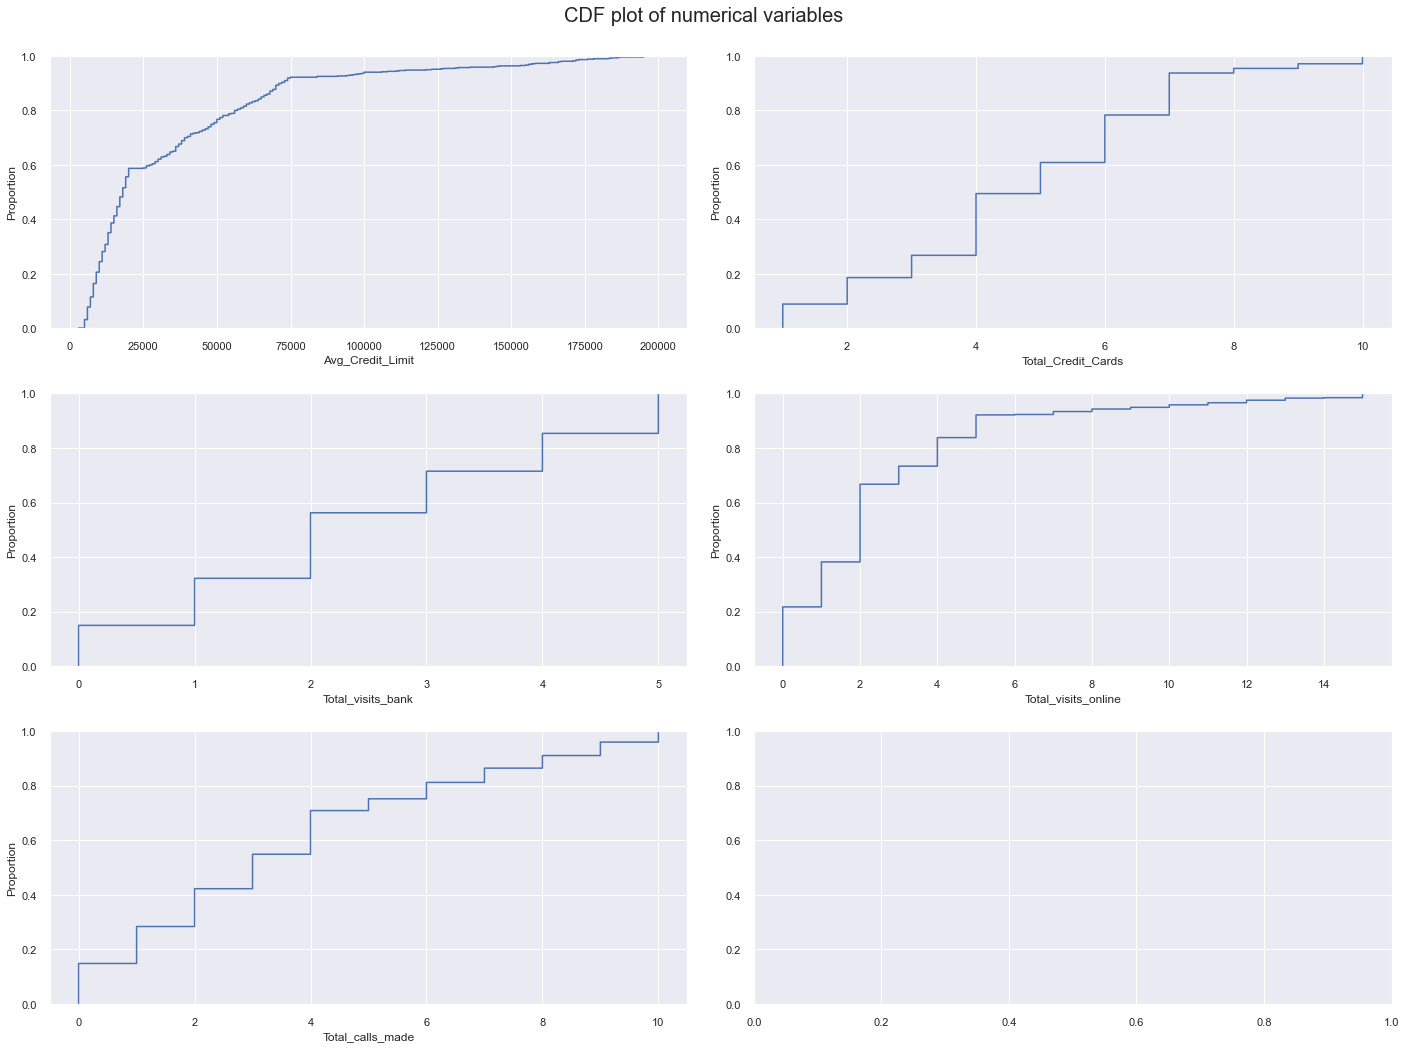

In [258]:
# select numerical columns
all_col = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(3, 2,  figsize=(20, 15))
fig.suptitle('CDF plot of numerical variables', fontsize=20)
counter = 0
for ii in range(3):
    sns.ecdfplot(ax=axes[ii][0],x=df[all_col[counter]])
    counter = counter+1
    if counter != 5:
        sns.ecdfplot(ax=axes[ii][1],x=df[all_col[counter]])
        counter = counter+1
    else:
        pass


fig.tight_layout(pad=2.0)

## Bivariate Analysis

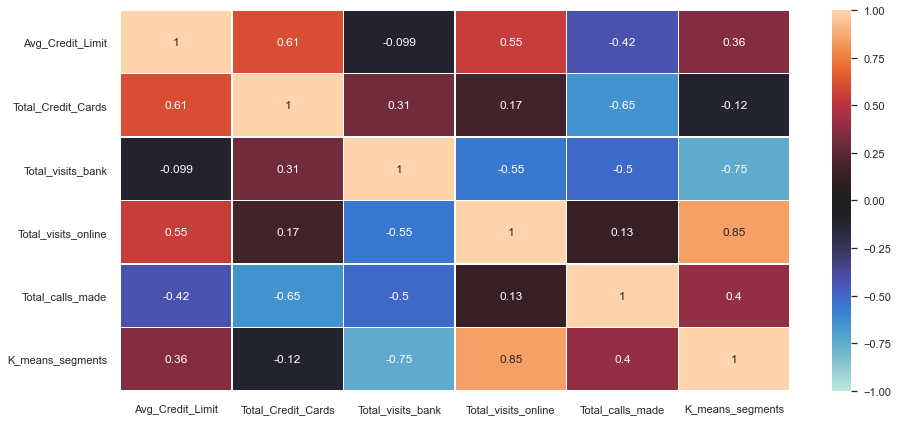

In [259]:
plt.figure(figsize=(15,7))

sns.heatmap(df[all_col].corr(),
            annot=True,
            linewidths=0.5,vmin=-1,vmax=1,
            center=0,
            cbar=True,)            

plt.show()

##### Observations: Average credit limit has a high relationship with the total credit cards. Total calls made and average credit limit and total credit cards have a negative relationship. Online versus bank visits have a negative relationship.

<AxesSubplot:xlabel='Avg_Credit_Limit', ylabel='Total_calls_made'>

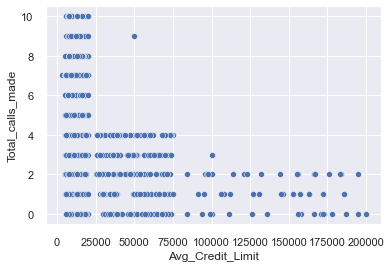

In [331]:
sns.scatterplot(x=df.Avg_Credit_Limit,y=df.Total_calls_made)

In [261]:
# variables used for clustering
all_col

['Avg_Credit_Limit',
 'Total_Credit_Cards',
 'Total_visits_bank',
 'Total_visits_online',
 'Total_calls_made',
 'K_means_segments']

In [262]:
# Scaling the dataset before clustering
scaler=StandardScaler()
subset=df[all_col].copy()
subset_scaled=scaler.fit_transform(subset) 

In [263]:
# Creating a dataframe of the above results
subset_scaled_df=pd.DataFrame(subset_scaled,columns=subset.columns)

### KMeans Clustering, Elbow Curve and Silhouette Scoring

Number of Clusters: 1 	Average Distortion: 2.217063661148065
Number of Clusters: 2 	Average Distortion: 1.5522119081954742
Number of Clusters: 3 	Average Distortion: 1.1434401208195095
Number of Clusters: 4 	Average Distortion: 1.0443313229704776
Number of Clusters: 5 	Average Distortion: 0.9880591433704322
Number of Clusters: 6 	Average Distortion: 0.9404952836425913
Number of Clusters: 7 	Average Distortion: 0.9072700735933968
Number of Clusters: 8 	Average Distortion: 0.8877652766597075


Text(0.5, 1.0, 'Selecting k with the Elbow Method')

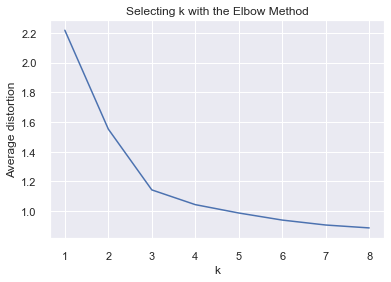

In [264]:
clusters=range(1,9)
meanDistortions=[]

for k in clusters:
    model=KMeans(n_clusters=k)
    model.fit(subset_scaled_df)
    prediction=model.predict(subset_scaled_df)
    distortion=sum(np.min(cdist(subset_scaled_df, model.cluster_centers_, 'euclidean'), axis=1)) / subset_scaled_df.shape[0]
                           
    meanDistortions.append(distortion)

    print('Number of Clusters:', k, '\tAverage Distortion:', distortion)

plt.plot(clusters, meanDistortions, 'bx-')
plt.xlabel('k')
plt.ylabel('Average distortion')
plt.title('Selecting k with the Elbow Method')

#### Observations: Appropriate k seems to be 3 or 4

For n_clusters = 2, silhouette score is 0.48412764695996535)
For n_clusters = 3, silhouette score is 0.5715521721560776)
For n_clusters = 4, silhouette score is 0.38506571838219805)
For n_clusters = 5, silhouette score is 0.2802958644769454)
For n_clusters = 6, silhouette score is 0.25431900630758336)
For n_clusters = 7, silhouette score is 0.25743322675219127)
For n_clusters = 8, silhouette score is 0.2296850592483034)
For n_clusters = 9, silhouette score is 0.22431381718410734)


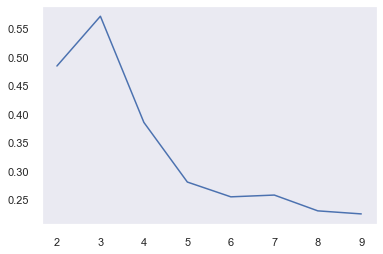

In [265]:
sil_score = []
cluster_list = list(range(2,10))
for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters)
    preds = clusterer.fit_predict((subset_scaled_df))
    #centers = clusterer.cluster_centers_
    score = silhouette_score(subset_scaled_df, preds)
    sil_score.append(score)
    print("For n_clusters = {}, silhouette score is {})".format(n_clusters, score))

plt.plot(cluster_list,sil_score)
plt.grid()

#### Observations: Silhouette score for 3 is high, so we choose 3 as the value of k

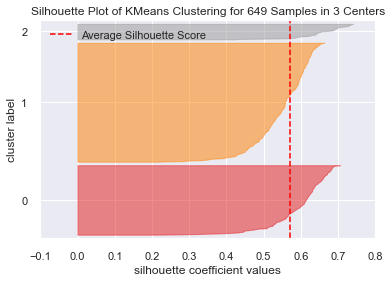

In [266]:
# Finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(3, random_state = 1))
visualizer.fit(subset_scaled_df)    
visualizer.show();


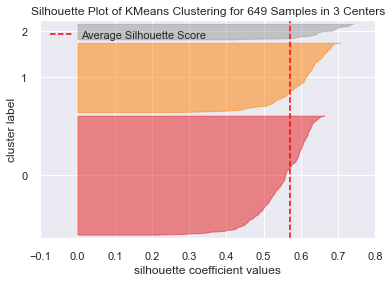

In [267]:
#Finding optimal no. of clusters with silhouette coefficients
visualizer = SilhouetteVisualizer(KMeans(3, random_state = 1))
visualizer.fit(subset_scaled_df)    
visualizer.show();

### Hierarchical clustering

In [306]:
# Reading the full dataset again 
custdata=pd.read_csv('Credit Card Customer Data.csv')

In [307]:
custdata.head(10)

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3
5,6,58634,20000,3,0,1,8
6,7,48370,100000,5,0,11,2
7,8,37376,15000,3,0,1,1
8,9,82490,5000,2,0,2,2
9,10,44770,3000,4,0,1,7


In [314]:
custdataAttr=custdata.iloc[:,2:]
custdataAttr.head(10)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3
5,20000,3,0,1,8
6,100000,5,0,11,2
7,15000,3,0,1,1
8,5000,2,0,2,2
9,3000,4,0,1,7


#### Observations: Before going any further we must apply the zscore to the columns so that the Avg_Credit_limit col does not misrepresent the data.

In [315]:
## for better visual display of our data we apply the zscore and scale
custdataScaled=custdataAttr.apply(zscore)
custdataScaled.head(10)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1.740187,-1.249225,-0.860451,-0.547490,-1.251537
1,0.410293,-0.787585,-1.473731,2.520519,1.891859
2,0.410293,1.058973,-0.860451,0.134290,0.145528
3,-0.121665,0.135694,-0.860451,-0.547490,0.145528
4,1.740187,0.597334,-1.473731,3.202298,-0.203739
5,-0.387644,-0.787585,-1.473731,-0.547490,1.542593
6,1.740187,0.135694,-1.473731,2.861408,-0.553005
7,-0.520633,-0.787585,-1.473731,-0.547490,-0.902271
8,-0.786612,-1.249225,-1.473731,-0.206600,-0.553005
9,-0.839808,-0.325946,-1.473731,-0.547490,1.193326


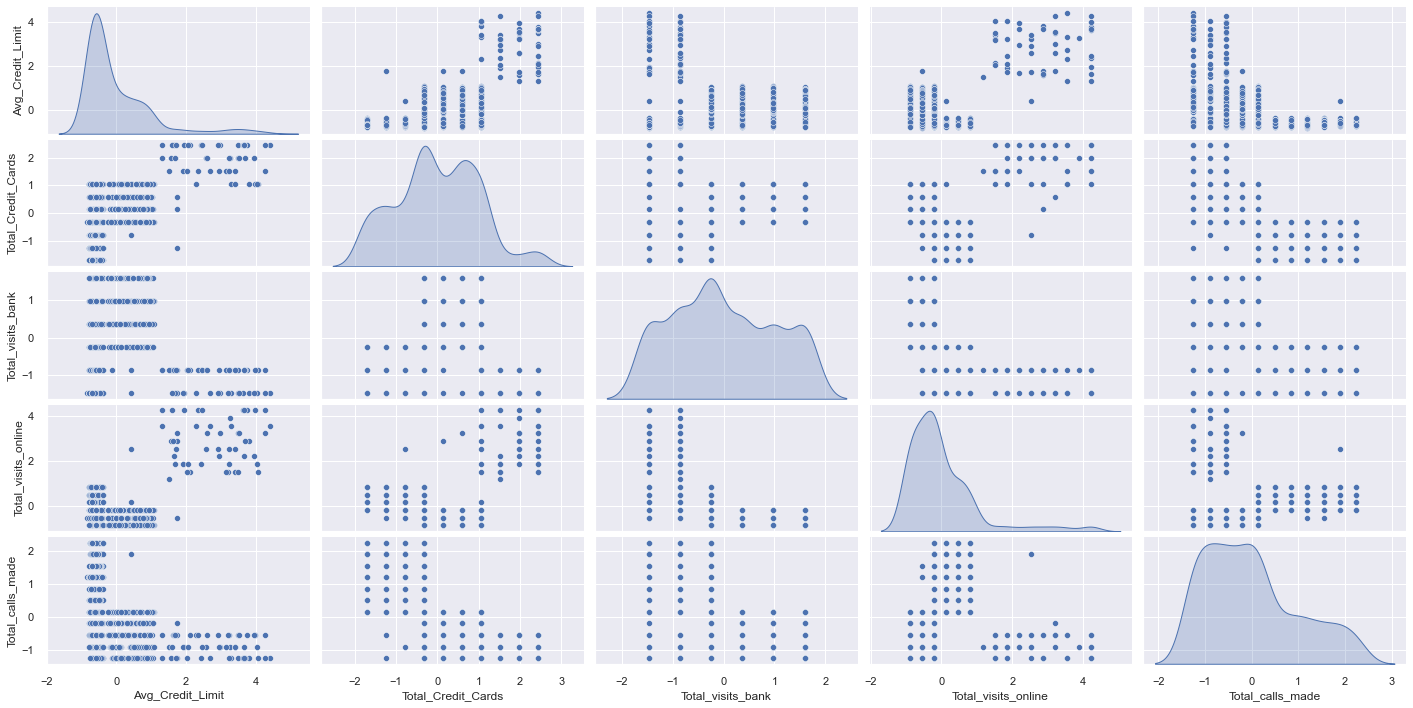

In [316]:
#importing seaborn for statistical plots
sns.pairplot(custdataScaled, height=2,aspect=2 , diag_kind='kde')

In [317]:
from sklearn.cluster import AgglomerativeClustering
from scipy.spatial.distance import pdist  #Pairwise distribution between data points

In [322]:
model = AgglomerativeClustering(n_clusters=3, affinity='cityblock',  linkage='average')

In [323]:
model.fit(custdataScaled)

AgglomerativeClustering(affinity='cityblock', linkage='average', n_clusters=3)

In [326]:
custdataAttr['labels'] = model.labels_
custdataAttr.head()


<ipython-input-326-11596ca7b6a2>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  custdataAttr['labels'] = model.labels_


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,labels
0,100000,2,1,1,0,0
1,50000,3,0,10,9,2
2,50000,7,1,3,4,0
3,30000,5,1,1,4,0
4,100000,6,0,12,3,1


In [352]:
custdataClust = custdataAttr.groupby(['labels'])

In [353]:
custdataClust.mean()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
labels,,,,,
0,33713.178,5.512,3.486,0.984,2.005
1,141040.000,8.740,0.600,10.900,1.080
2,12197.309,2.404,0.928,3.561,6.883


In [359]:
# cophenet index is a measure of the correlation between the distance of points in feature space and distance on dendrogram
# closer it is to 1, the better is the clustering

Z = linkage(custdataScaled, metric='cityblock', method='average')
c, coph_dists = cophenet(Z , pdist(custdataScaled))

c

0.896329431104133

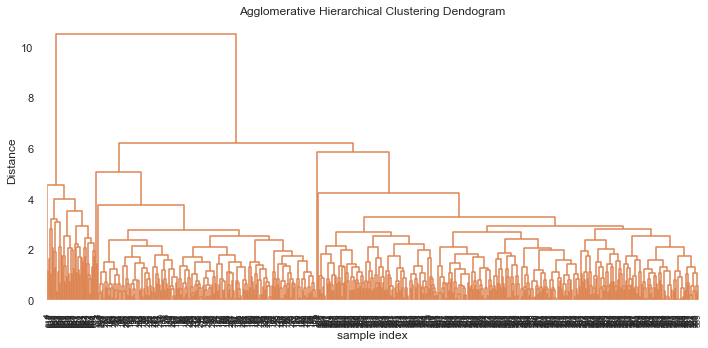

In [360]:
plt.figure(figsize=(10, 5))
plt.title('Agglomerative Hierarchical Clustering Dendogram')
plt.xlabel('sample index')
plt.ylabel('Distance')
dendrogram(Z, leaf_rotation=90.,color_threshold = 40, leaf_font_size=8. )
plt.tight_layout()

In [361]:
# cophenet index is a measure of the correlation between the distance of points in feature space and distance on dendrogram
# closer it is to 1, the better is the clustering

Z = linkage(custdataScaled, metric='euclidean', method='average')
c, coph_dists = cophenet(Z , pdist(custdataScaled))

c

0.8977080867389372

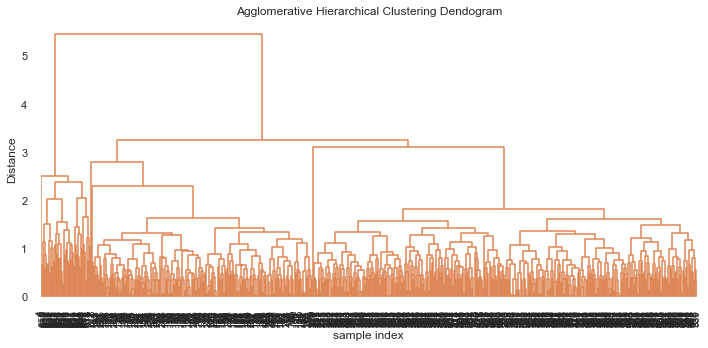

In [362]:
plt.figure(figsize=(10, 5))
plt.title('Agglomerative Hierarchical Clustering Dendogram')
plt.xlabel('sample index')
plt.ylabel('Distance')
dendrogram(Z, leaf_rotation=90.,color_threshold=90,  leaf_font_size=10. )
plt.tight_layout()

In [275]:
# cophenet index is a measure of the correlation between the distance of points in feature space and distance on dendrogram
# closer it is to 1, the better is the clustering
distance_metrics = [ 'euclidean','chebyshev','mahalanobis','cityblock']
linkage_methods = ['single', 'complete', 'average', 'weighted']
high_cophenet_corr = 0
high_dm_lm = [0,0]
for dm in distance_metrics:
    for lm in linkage_methods:
        Z = linkage(subset_scaled_df, metric=dm, method=lm)
        c, coph_dists = cophenet(Z , pdist(subset_scaled_df))
        print('Cophent correlation for distance metrics {} and linkahe method {} is {}'.format(dm,lm,c))
        if high_cophenet_corr < c:
            high_cophenet_corr = c
            high_dm_lm[0] = dm
            high_dm_lm[1] = lm

Cophent correlation for distance metrics euclidean and linkahe method single is 0.8978538751523425
Cophent correlation for distance metrics euclidean and linkahe method complete is 0.8837002394146526
Cophent correlation for distance metrics euclidean and linkahe method average is 0.9100963201569814
Cophent correlation for distance metrics euclidean and linkahe method weighted is 0.9052656121003184
Cophent correlation for distance metrics chebyshev and linkahe method single is 0.8118063771075958
Cophent correlation for distance metrics chebyshev and linkahe method complete is 0.8672376803928954
Cophent correlation for distance metrics chebyshev and linkahe method average is 0.9086066909752651
Cophent correlation for distance metrics chebyshev and linkahe method weighted is 0.88484300133361
Cophent correlation for distance metrics mahalanobis and linkahe method single is 0.8652242698029385
Cophent correlation for distance metrics mahalanobis and linkahe method complete is 0.4889077065176

In [276]:
print('Highest cophenet correlation is {}, which is obtinaed with {} distance metric and {} linkage method'.format(high_cophenet_corr ,high_dm_lm[0],high_dm_lm[1]))

Highest cophenet correlation is 0.9100963201569814, which is obtinaed with euclidean distance metric and average linkage method


### Lets explore 'centroid', 'median','ward' linkage method which requires only Euclidean distance metrics

In [277]:
linkage_methods = ['single', 'complete', 'average','median','ward', 'weighted']
high_cophenet_corr = 0
high_dm_lm = [0,0]

for lm in linkage_methods:
    Z = linkage(subset_scaled_df, metric='euclidean', method=lm)
    c, coph_dists = cophenet(Z , pdist(subset_scaled_df))
    print('Cophent correlation for distance metrics {} and linkahe method {} is {}'.format('euclidean',lm,c))
    if high_cophenet_corr < c:
        high_cophenet_corr = c
        high_dm_lm[0] = dm
        high_dm_lm[1] = lm
print('*'*110)
print('Highest cophenet correlation is {}, which is obtinaed with {} distance metric and {} linkage method'.format(high_cophenet_corr ,high_dm_lm[0],high_dm_lm[1]))

Cophent correlation for distance metrics euclidean and linkahe method single is 0.8978538751523425
Cophent correlation for distance metrics euclidean and linkahe method complete is 0.8837002394146526
Cophent correlation for distance metrics euclidean and linkahe method average is 0.9100963201569814
Cophent correlation for distance metrics euclidean and linkahe method median is 0.8803969069337012
Cophent correlation for distance metrics euclidean and linkahe method ward is 0.7576535233745099
Cophent correlation for distance metrics euclidean and linkahe method weighted is 0.9052656121003184
**************************************************************************************************************
Highest cophenet correlation is 0.9100963201569814, which is obtinaed with cityblock distance metric and average linkage method


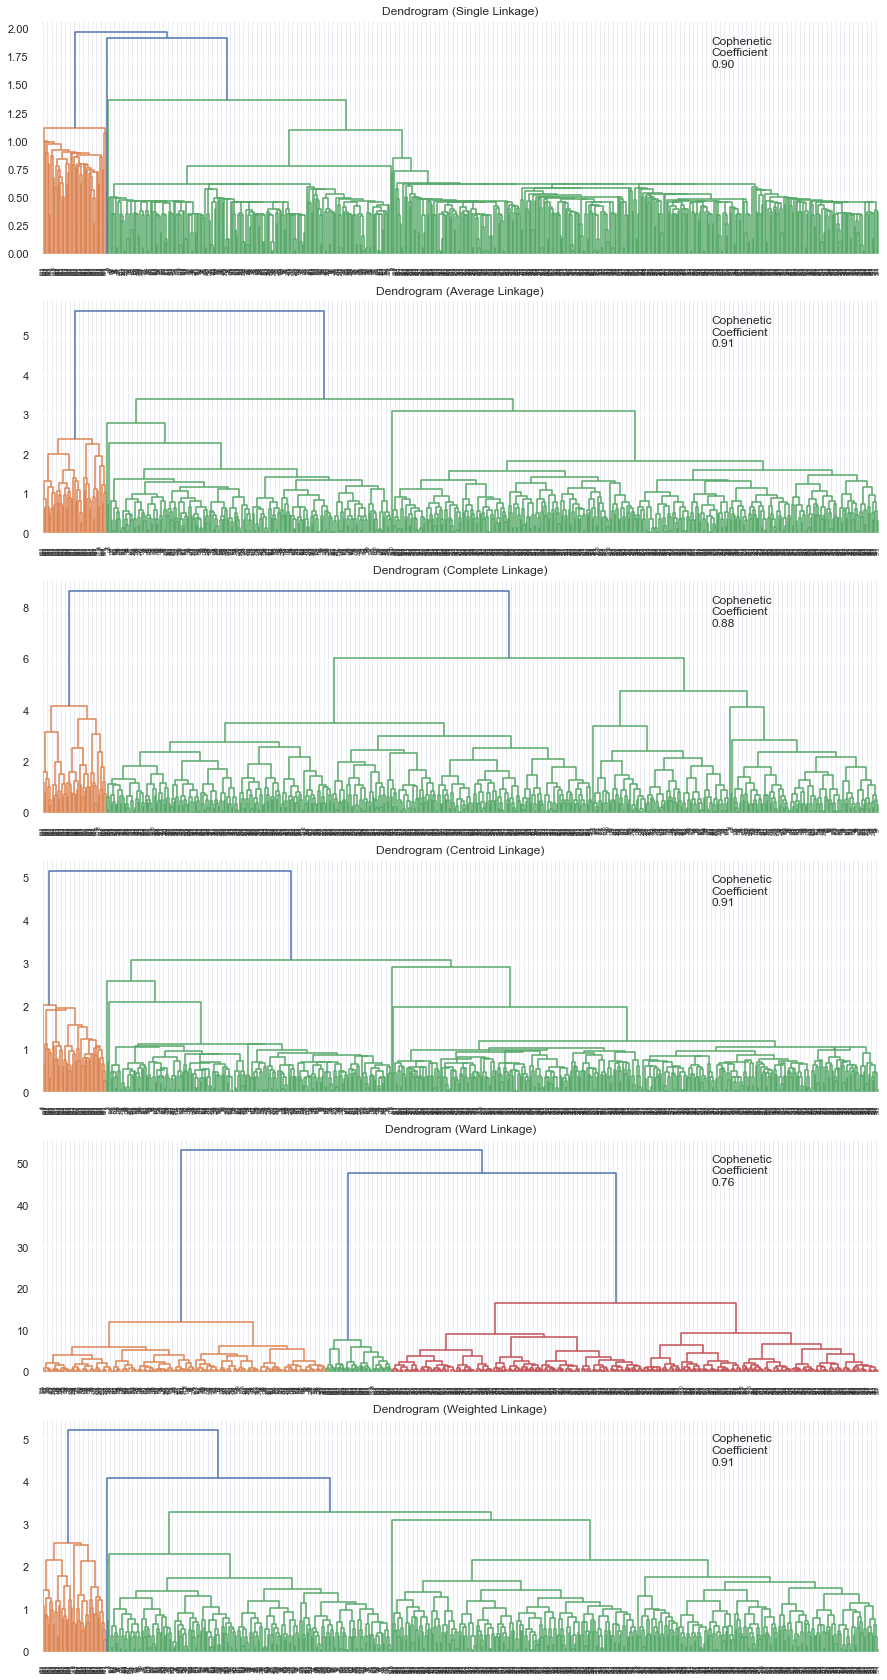

In [278]:
# List of all linkage methods to check
methods = ['single',
           'average', 
           'complete',
           'centroid',
           'ward',
          'weighted']

# Calculate the pairwise distance form the dataset to be used in the cophenetic correlation calculation
#pw_distance = pdist(credit_scaled)

# Create lists to save results of coph calculation
compare_cols = ['Linkage', 'Cophenetic Coefficient']
compare = []

# Create a subplot image
fig, axs = plt.subplots(len(methods), 1, figsize=(15, 30))

# Enumerate through the list of all methods above
# Get linkage, plot dendrogram, calculate cophenetic coefficient
for i, method in enumerate(methods):
    
    Z = linkage(subset_scaled_df, metric='euclidean', method=method)

    dendrogram(Z, ax=axs[i]);
    axs[i].set_title(f'Dendrogram ({method.capitalize()} Linkage)')
    coph_corr, coph_dist = cophenet(Z, pdist(subset_scaled_df))
    axs[i].annotate(f'Cophenetic\nCoefficient\n{coph_corr:0.2f}', 
                    (0.80, 0.80),
                    xycoords='axes fraction')
    compare.append([method, coph_corr])

#### Observations: The dendrogram with weighted linkage method gave us 3 distinct clusters. Three clusters will be used going forward using the weighted linkage method.

#### Observations:Dendrogram with ward linkage method shows distinct and separate clusters. However the dendrograms with Average and Weighted linkage have higher Cophenetic Coefficients.  

#### Based on the dendrograms above, using the cityblock distance metric and weighted linkage method, we can see 3 distnict clusters. Although there are higher cophenetic coefficents, this model best represents the data.

In [364]:
# Create and print dataframe to compare Cophenetic Coefficient for each linkage
df_cc = pd.DataFrame(compare, columns=compare_cols)
df_cc

,Linkage,Cophenetic Coefficient
0,single,0.898
1,average,0.910
2,complete,0.884
3,centroid,0.907
4,ward,0.758
5,weighted,0.905


#### Based on the dendrograms we have viewed the best results came from using the Centroid, Average & Weighted linkage methods with the Euclidean and Cityblock distance methods.

In [365]:
distance_metrics = [ 'euclidean','cityblock']
linkage_methods = ['average','weighted' ]

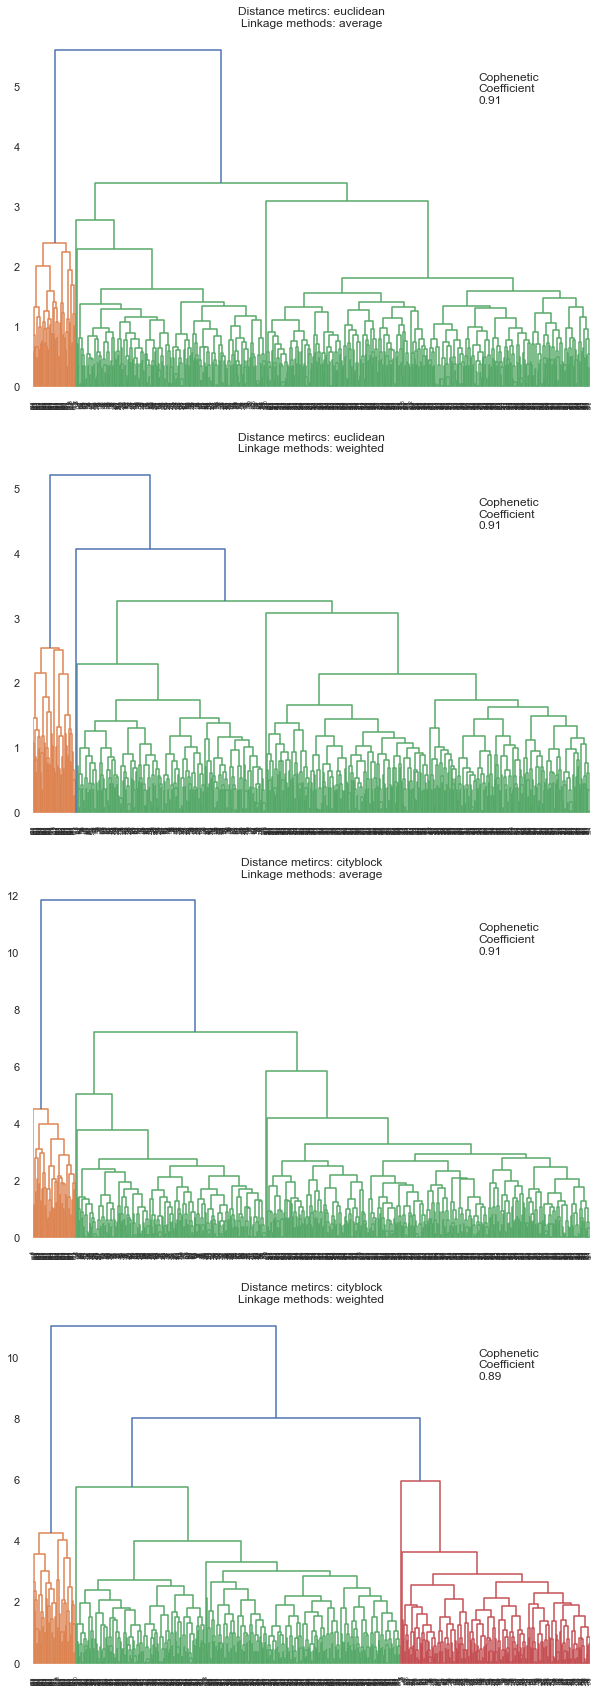

In [366]:
# Create a subplot image
fig, axs = plt.subplots(len(distance_metrics)+len(distance_metrics), 1, figsize=(10, 30))
i=0
for dm in distance_metrics:
    for lm in linkage_methods:
        Z = linkage(subset_scaled_df, metric=dm, method=lm)
        dendrogram(Z,  ax=axs[i]);
        axs[i].set_title('Distance metircs: {}\nLinkage methods: {}'.format(dm,lm))
        coph_corr, coph_dist = cophenet(Z, pdist(subset_scaled_df))
        axs[i].annotate(f'Cophenetic\nCoefficient\n{coph_corr:0.2f}', 
                        (0.80, 0.80),
                        xycoords='axes fraction')
        axs[i].set_title('Distance metircs: {}\nLinkage methods: {}'.format(dm,lm))                        
        i +=1
       

In [367]:
# lets us take 3 as number of clusters
kmeans = KMeans(n_clusters=3, random_state=0)
kmeans.fit(subset_scaled_df)

KMeans(n_clusters=3, random_state=0)

In [368]:
df['K_means_segments'] = kmeans.labels_
subset_scaled_df['K_means_segments'] = kmeans.labels_

In [369]:
cluster_profile = df.groupby('K_means_segments').mean()

In [370]:
cluster_profile['count_in_each_segments'] = df.groupby('K_means_segments')['Avg_Credit_Limit'].count().values

In [371]:
# lets display cluster profile
cluster_profile.style.highlight_max(color = 'lightgreen', axis = 0)

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,count_in_each_segments
K_means_segments,,,,,,
0,34071.428571,5.518519,3.484127,0.981481,1.992063,378
1,12239.819005,2.411765,0.945701,3.561086,6.891403,221
2,141040.000000,8.740000,0.600000,10.900000,1.080000,50


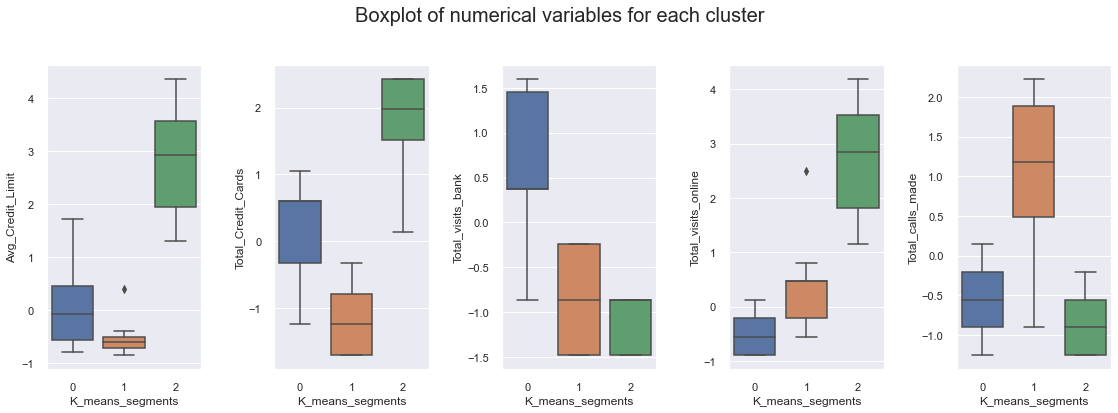

In [372]:
fig, axes = plt.subplots(1, 5,  figsize=(16, 6))
fig.suptitle('Boxplot of numerical variables for each cluster', fontsize=20)
counter = 0
for ii in range(5):
    sns.boxplot(ax=axes[ii],y=subset_scaled_df[all_col[counter]],x=subset_scaled_df['K_means_segments'])
    counter = counter+1

fig.tight_layout(pad=2.0)

In [375]:
pd.crosstab(df['K_means_segments'], df.Avg_Credit_Limit).style.highlight_max(color = 'lightgreen', axis = 0)

Avg_Credit_Limit,3000,5000,6000,7000,8000,9000,10000,11000,12000,13000,14000,15000,16000,17000,18000,19000,20000,25000,26000,27000,28000,29000,30000,31000,32000,33000,34000,35000,36000,37000,38000,39000,40000,41000,42000,43000,44000,45000,46000,47000,48000,49000,50000,51000,52000,54000,55000,56000,57000,58000,59000,60000,61000,62000,63000,64000,65000,66000,67000,68000,69000,70000,71000,72000,73000,74000,75000,84000,91000,94000,95000,96000,97000,98000,99000,100000,106000,108000,111000,112000,114000,121000,123000,126000,127000,131000,132000,136000,144000,145000,146000,153000,155000,156000,157000,158000,163000,166000,167000,171000,172000,173000,176000,178000,183000,184000,186000,187000,195000,200000
K_means_segments,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
0,0,7,14,11,14,9,11,9,9,10,9,6,9,10,13,13,7,1,5,2,3,5,6,5,2,4,6,2,11,6,8,7,3,6,2,1,3,3,3,5,6,4,7,4,5,4,1,7,3,3,4,5,3,3,2,4,5,4,3,7,4,10,4,3,4,6,2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1,13,16,13,18,18,14,15,8,18,14,11,13,13,9,13,13,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,1,2,2,1,1,2,1,1,1,1,1,1,1,2,1


#### Observations: The higher the credit limit the more credit cards the customer has. 


##### Business Recommendations: More calls to customers with higher credit limits. Increase online marketing since customers with higher credit limits use the online portal versus bank visits. Reduce the number of calls to clients with lower credit limits. 